# Cyber Fraud Risk Prediction and Cybersecurity Awareness Analysis
## End-to-End Data Science & Machine Learning Pipeline
**Department of Data Science & Computer Science**  
*Converted from Streamlit Interactive Application (pp.py) and ML Training Pipeline (	rain_models.py)*

---

### Notebook Outline
1. **Environment Setup & Data Loading**
2. **Exploratory Data Analysis (EDA)** (Visualizing Scam Outcomes, Age Cohorts, Payment Volume, Scam Typologies, Awareness & Security Hygiene)
3. **Feature Engineering & Leak-Free Target Formulation** (Fraud_Victim)
4. **Machine Learning Model Training** (Baseline Dummy, Logistic Regression, Decision Tree, Random Forest)
5. **Model Evaluation & Diagnostic Comparison** (Accuracy, Precision, Recall, F1, Confusion Matrices, ROC Curves)
6. **Random Forest Feature Importance Analysis**
7. **Interactive Cyber Fraud Risk Simulator** (Streamlit Tab 9 logic converted into a Python simulator)
8. **Stratified K-Fold Cross-Validation** (Model stability check)


In [1]:
import os
import re
import json
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, auc
)

# Plotting style configuration matching app.py
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.edgecolor"] = "#CCCCCC"
plt.rcParams["axes.linewidth"] = 0.8
plt.rcParams["grid.color"] = "#EBEBEB"
plt.rcParams["grid.linestyle"] = "--"
print("Libraries imported successfully.")


Libraries imported successfully.


---
### 1. Dataset Loading & Inspection
We load the survey dataset (cleaned_cyber_fraud.csv) and inspect its dimensions, schema, and completeness.


In [2]:
# Path resolution for standalone or nested project execution
candidates = [
    Path("dataset/cleaned_cyber_fraud.csv"),
    Path("cleaned_cyber_fraud.csv"),
    Path("../dataset/cleaned_cyber_fraud.csv"),
    Path("CyberFraudPrediction/dataset/cleaned_cyber_fraud.csv"),
    Path("CyberFraudPrediction/cleaned_cyber_fraud.csv")
]

data_path = None
for p in candidates:
    if p.exists():
        data_path = p
        break

if data_path is None:
    raise FileNotFoundError("Could not find 'cleaned_cyber_fraud.csv'. Ensure the dataset exists.")

print(f"Loading cleaned dataset from: {data_path.resolve()}")
df_clean = pd.read_csv(data_path)
print(f"Dataset Dimensions: {df_clean.shape[0]} rows, {df_clean.shape[1]} columns")
df_clean.head()


Loading cleaned dataset from: C:\Channesh\CyberFraudPrediction\dataset\cleaned_cyber_fraud.csv
Dataset Dimensions: 1509 rows, 16 columns


,Name,Age_Group,Social_Media_Hours,Digital_Transactions_Per_Week,Social_Media_Scam_Exposure,Social_Media_Scam_Type,Personal_Social_Media_Fraud_Loss,Social_Media_Scam_Outcome,Suspicious_Payment_UPI_QR_Exposure,Transaction_Fraud_Loss,Suspicious_Link_Exposure,OTP_Password_Request_Exposure,Suspicious_Link_Clicks,Security_Practices,Fraud_Identification_Ability,Overall_Cybersecurity_Awareness
0,Shristi Pal,18-25,2-4 hours,More than 14 times / week,2-3 times,Fake/impersonation account; Romance/relationsh...,Less than Rs. 500,Ignored/blocked it,Never,Less than Rs. 500,Rarely,Never,Never,Often,3 - Average,4
1,Anand Prakash,18-25,1-2 hours,More than 14 times / week,2-3 times,Fake giveaway/prize; Fake job offer; Romance/r...,"Rs. 2,000 - Rs. 5,000",Clicked the link but no loss occurred,Once,No,Rarely,Once,Once,Often,3 - Average,4
2,Mritunjai Singh,18-25,1-2 hours,4-7 times / week,More than 5 times,Fake giveaway/prize; Fake job offer; Shopping/...,Not sure,Ignored/blocked it,2-3 times,No,Rarely,Never,More than 5 times,Often,5 - Excellent,4
3,Ritu Kumari,18-25,2-4 hours,More than 14 times / week,2-3 times,Fake giveaway/prize,Not sure,Ignored/blocked it,Never,No,Rarely,Never,Never,Often,3 - Average,3
4,Sumit Mahajan,18-25,1-2 hours,1-3 times / week,4-5 times,Fake/impersonation account,Less than Rs. 500,Ignored/blocked it,Once,"Rs. 500 - Rs. 2,000",Rarely,2-3 times,4-5 times,Rarely,2 - Poor,3


In [3]:
# Missing values and duplicate auditing
print("Missing Values Check:")
print(df_clean.isnull().sum())
print(f"\nTotal Duplicate Records: {df_clean.duplicated().sum()}")


Missing Values Check:
Name                                  0
Age_Group                             0
Social_Media_Hours                    0
Digital_Transactions_Per_Week         0
Social_Media_Scam_Exposure            0
Social_Media_Scam_Type                0
Personal_Social_Media_Fraud_Loss      0
Social_Media_Scam_Outcome             0
Suspicious_Payment_UPI_QR_Exposure    0
Transaction_Fraud_Loss                0
Suspicious_Link_Exposure              0
OTP_Password_Request_Exposure         0
Suspicious_Link_Clicks                0
Security_Practices                    0
Fraud_Identification_Ability          0
Overall_Cybersecurity_Awareness       0
dtype: int64

Total Duplicate Records: 0


---
### 2. Exploratory Data Analysis (Replicating app.py Visualizations)
Here we replicate the 6 visual analyses featured in Tabs 2 through 7 of pp.py:
- Scam encounter outcomes
- Age cohort distribution & cross-tabulation
- Digital transaction frequency & fraud losses
- Multi-label scam typology breakdown
- Cybersecurity awareness & security hygiene adherence


C:\Users\Manish\AppData\Local\Temp\ipykernel_20240\3768261812.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


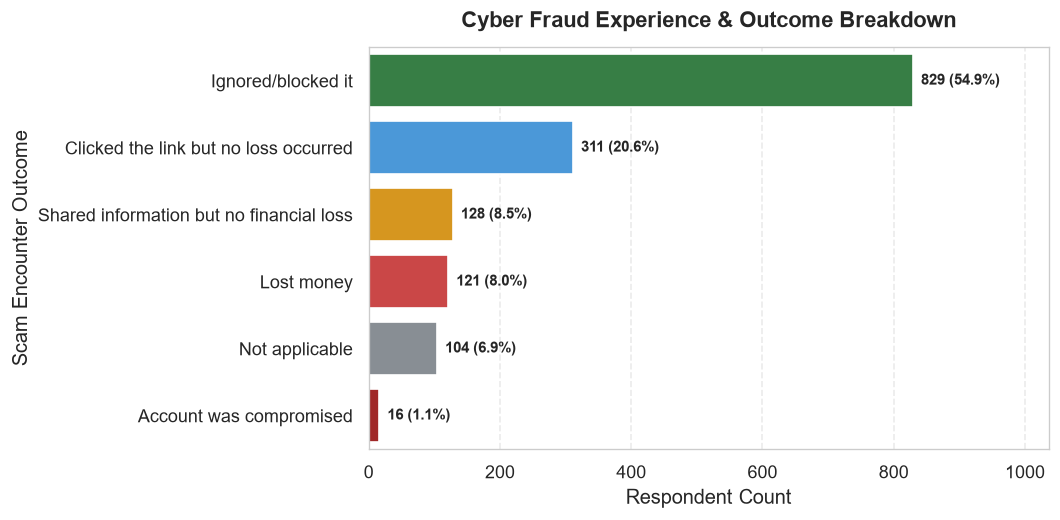

,Scam Encounter Outcome,Respondent Count,Percentage
0,Ignored/blocked it,829,54.9%
1,Clicked the link but no loss occurred,311,20.6%
2,Shared information but no financial loss,128,8.5%
3,Lost money,121,8.0%
4,Not applicable,104,6.9%
5,Account was compromised,16,1.1%


In [4]:
# 2.1 Scam Encounter Outcomes (Matching app.py Tab 2)
outcome_counts = df_clean["Social_Media_Scam_Outcome"].value_counts().reset_index()
outcome_counts.columns = ["Scam Encounter Outcome", "Respondent Count"]
outcome_counts["Percentage"] = (outcome_counts["Respondent Count"] / len(df_clean) * 100).round(1).astype(str) + "%"

plt.figure(figsize=(9, 4.5))
palette = ["#2b8a3e", "#339af0", "#f59f00", "#e03131", "#868e96", "#b41414"]
ax = sns.barplot(
    data=outcome_counts,
    y="Scam Encounter Outcome",
    x="Respondent Count",
    palette=palette[:len(outcome_counts)]
)
plt.title("Cyber Fraud Experience & Outcome Breakdown", fontsize=13, fontweight="bold", pad=12)
for p in ax.patches:
    w = p.get_width()
    pct = (w / len(df_clean)) * 100
    ax.annotate(f"{int(w)} ({pct:.1f}%)", (w + max(outcome_counts["Respondent Count"])*0.015, p.get_y() + p.get_height()/2), va="center", fontsize=9, fontweight="bold")
plt.xlim(0, max(outcome_counts["Respondent Count"]) * 1.25)
plt.tight_layout()
plt.show()

display(outcome_counts)


C:\Users\Manish\AppData\Local\Temp\ipykernel_20240\2523225926.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts_age.index, y=counts_age.values, palette="Blues_r", ax=axes[0])


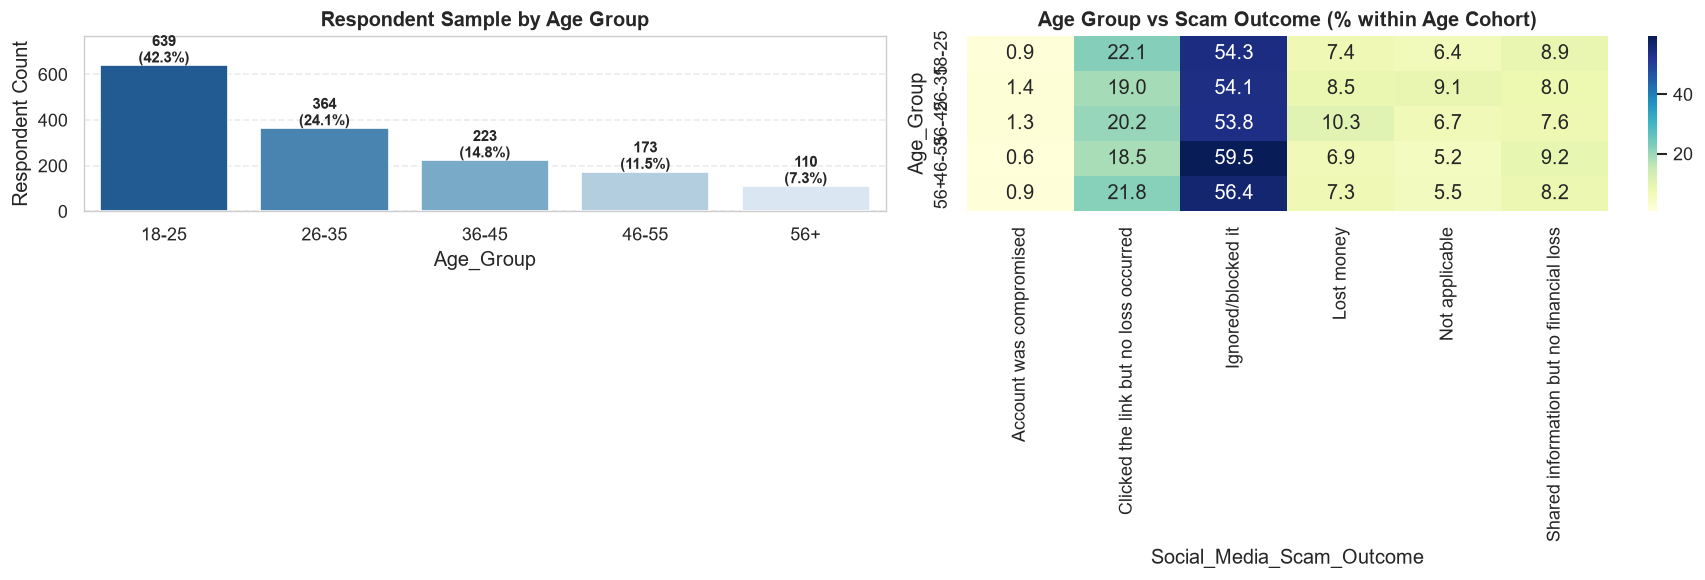

In [5]:
# 2.2 Age Group Distribution & Cross-Tabulation (Matching app.py Tab 3)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Age distribution bar plot
age_order = ["18-25", "26-35", "36-45", "46-55", "56+"]
counts_age = df_clean["Age_Group"].value_counts().reindex(age_order).fillna(0)
sns.barplot(x=counts_age.index, y=counts_age.values, palette="Blues_r", ax=axes[0])
axes[0].set_title("Respondent Sample by Age Group", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Respondent Count")
for p in axes[0].patches:
    h = p.get_height()
    pct = (h / len(df_clean)) * 100 if len(df_clean) > 0 else 0
    axes[0].annotate(f"{int(h)}\n({pct:.1f}%)", (p.get_x() + p.get_width()/2, h + max(counts_age.values)*0.02), ha="center", fontsize=9, fontweight="bold")
axes[0].set_ylim(0, max(counts_age.values) * 1.2)

# Cross-tabulation heatmap (Age Group vs Outcome)
ct_age = pd.crosstab(df_clean["Age_Group"], df_clean["Social_Media_Scam_Outcome"], normalize="index") * 100
sns.heatmap(ct_age, annot=True, fmt=".1f", cmap="YlGnBu", cbar=True, ax=axes[1])
axes[1].set_title("Age Group vs Scam Outcome (% within Age Cohort)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


C:\Users\Manish\AppData\Local\Temp\ipykernel_20240\3586819695.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=tx_counts, y="Frequency", x="Count", palette="crest_r", ax=axes[0])
C:\Users\Manish\AppData\Local\Temp\ipykernel_20240\3586819695.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=loss_counts, y="Loss Bracket", x="Count", palette="YlOrRd_r", ax=axes[1])


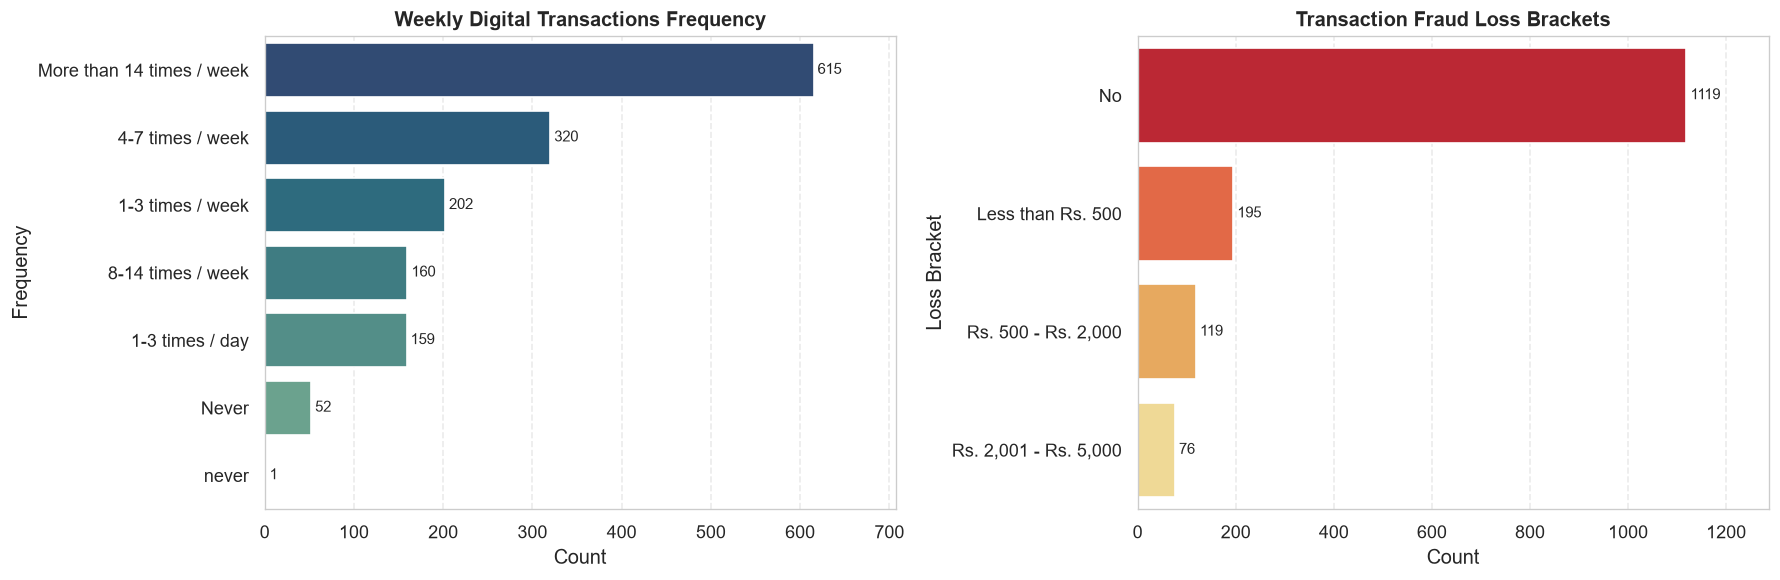

In [6]:
# 2.3 Digital Payment Frequency vs Fraud Loss (Matching app.py Tab 4)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Payment frequency
tx_counts = df_clean["Digital_Transactions_Per_Week"].value_counts().reset_index()
tx_counts.columns = ["Frequency", "Count"]
sns.barplot(data=tx_counts, y="Frequency", x="Count", palette="crest_r", ax=axes[0])
axes[0].set_title("Weekly Digital Transactions Frequency", fontsize=12, fontweight="bold")
for p in axes[0].patches:
    w = p.get_width()
    axes[0].annotate(f" {int(w)}", (w, p.get_y() + p.get_height()/2), va="center", fontsize=9)
axes[0].set_xlim(0, max(tx_counts["Count"]) * 1.15)

# Fraud loss brackets
loss_counts = df_clean["Transaction_Fraud_Loss"].value_counts().reset_index()
loss_counts.columns = ["Loss Bracket", "Count"]
sns.barplot(data=loss_counts, y="Loss Bracket", x="Count", palette="YlOrRd_r", ax=axes[1])
axes[1].set_title("Transaction Fraud Loss Brackets", fontsize=12, fontweight="bold")
for p in axes[1].patches:
    w = p.get_width()
    axes[1].annotate(f" {int(w)}", (w, p.get_y() + p.get_height()/2), va="center", fontsize=9)
axes[1].set_xlim(0, max(loss_counts["Count"]) * 1.15)

plt.tight_layout()
plt.show()


C:\Users\Manish\AppData\Local\Temp\ipykernel_20240\606069633.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=scam_df, y="Scam Category", x="Encounter Count", palette="flare_r")


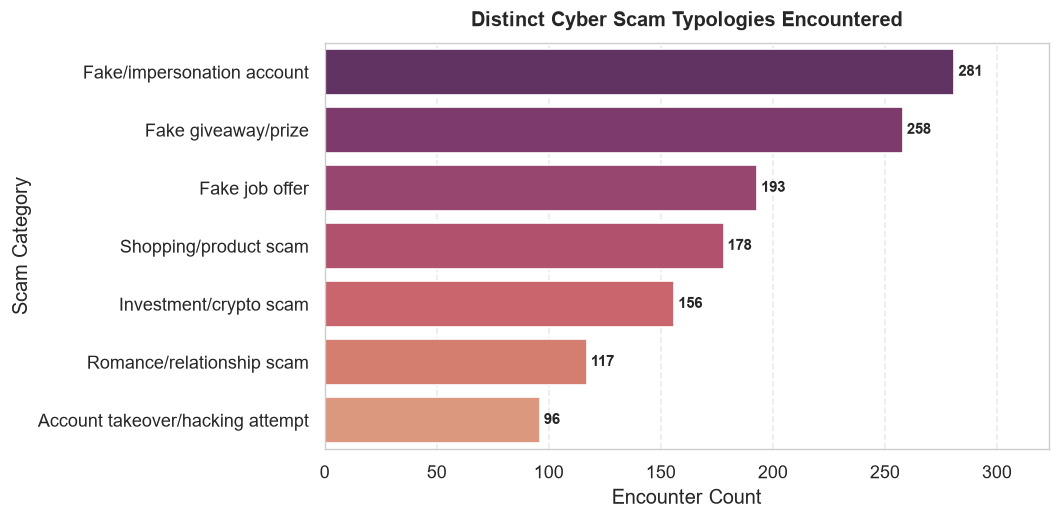

,Scam Category,Encounter Count,Percentage of Respondents
0,Fake/impersonation account,281,18.6%
1,Fake giveaway/prize,258,17.1%
2,Fake job offer,193,12.8%
3,Shopping/product scam,178,11.8%
4,Investment/crypto scam,156,10.3%
5,Romance/relationship scam,117,7.8%
6,Account takeover/hacking attempt,96,6.4%


In [7]:
# 2.4 Multi-Label Scam Typology Breakdown (Matching app.py Tab 5)
all_scams = []
for item in df_clean["Social_Media_Scam_Type"].dropna():
    for s in str(item).split(";"):
        cleaned_s = s.strip()
        if cleaned_s and cleaned_s.lower() != "not applicable":
            all_scams.append(cleaned_s)

scam_df = pd.Series(all_scams).value_counts().reset_index()
scam_df.columns = ["Scam Category", "Encounter Count"]
scam_df["Percentage of Respondents"] = (scam_df["Encounter Count"] / len(df_clean) * 100).round(1).astype(str) + "%"

plt.figure(figsize=(9, 4.5))
ax = sns.barplot(data=scam_df, y="Scam Category", x="Encounter Count", palette="flare_r")
plt.title("Distinct Cyber Scam Typologies Encountered", fontsize=12, fontweight="bold", pad=10)
for p in ax.patches:
    w = p.get_width()
    ax.annotate(f" {int(w)}", (w, p.get_y() + p.get_height()/2), va="center", fontsize=9, fontweight="bold")
plt.xlim(0, max(scam_df["Encounter Count"]) * 1.15)
plt.tight_layout()
plt.show()

display(scam_df)


C:\Users\Manish\AppData\Local\Temp\ipykernel_20240\1617131149.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["1 (Very Low)", "2 (Low)", "3 (Moderate)", "4 (Good)", "5 (High)"], y=aw_counts.values, palette="coolwarm", ax=axes[0])
C:\Users\Manish\AppData\Local\Temp\ipykernel_20240\1617131149.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sec_counts.index, y=sec_counts.values, palette=["#2b8a3e", "#38d9a9", "#ffe066", "#ffa94d", "#fa5252"], ax=axes[1])


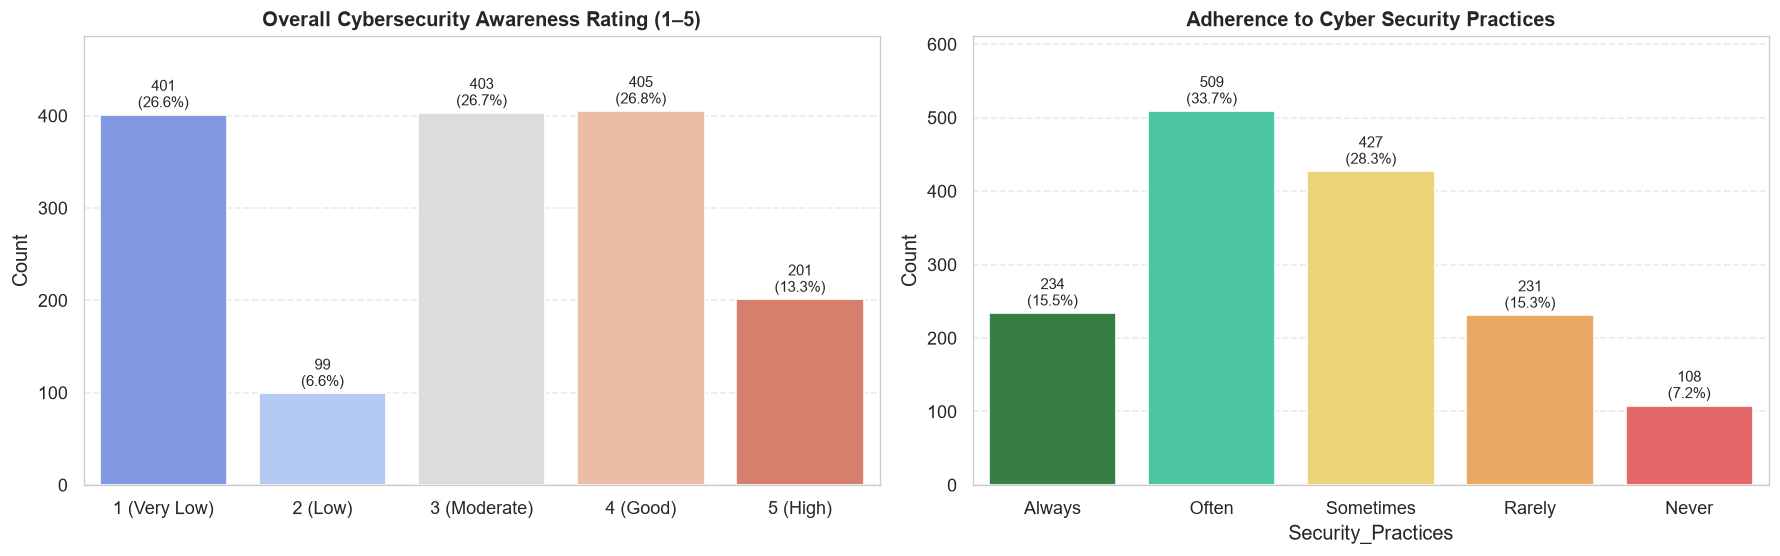

In [8]:
# 2.5 Cybersecurity Awareness & Daily Security Hygiene (Matching app.py Tabs 6 & 7)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

# Awareness rating
aw_counts = df_clean["Overall_Cybersecurity_Awareness"].value_counts().reindex([1, 2, 3, 4, 5]).fillna(0)
sns.barplot(x=["1 (Very Low)", "2 (Low)", "3 (Moderate)", "4 (Good)", "5 (High)"], y=aw_counts.values, palette="coolwarm", ax=axes[0])
axes[0].set_title("Overall Cybersecurity Awareness Rating (1–5)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Count")
for p in axes[0].patches:
    h = p.get_height()
    pct = (h / len(df_clean)) * 100 if len(df_clean) > 0 else 0
    axes[0].annotate(f"{int(h)}\n({pct:.1f}%)", (p.get_x() + p.get_width()/2, h + max(aw_counts.values)*0.02), ha="center", fontsize=9)
axes[0].set_ylim(0, max(aw_counts.values) * 1.2)

# Security practices adherence
sec_order = ["Always", "Often", "Sometimes", "Rarely", "Never"]
sec_counts = df_clean["Security_Practices"].value_counts().reindex(sec_order).fillna(0)
sns.barplot(x=sec_counts.index, y=sec_counts.values, palette=["#2b8a3e", "#38d9a9", "#ffe066", "#ffa94d", "#fa5252"], ax=axes[1])
axes[1].set_title("Adherence to Cyber Security Practices", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Count")
for p in axes[1].patches:
    h = p.get_height()
    pct = (h / len(df_clean)) * 100 if len(df_clean) > 0 else 0
    axes[1].annotate(f"{int(h)}\n({pct:.1f}%)", (p.get_x() + p.get_width()/2, h + max(sec_counts.values)*0.02), ha="center", fontsize=9)
axes[1].set_ylim(0, max(sec_counts.values) * 1.2)

plt.tight_layout()
plt.show()


---
### 3. Feature Engineering & Target Formulation
In this section, we build the prepared feature matrix:
1. **Target Variable (Fraud_Victim)**:
   - 1 = Experienced direct financial loss or compromised account.
   -   = Successfully avoided fraud harm.
2. **Data Leakage Safeguards**:
   - Post-attack outcome columns (Social_Media_Scam_Outcome, Personal_Social_Media_Fraud_Loss, Transaction_Fraud_Loss) and Name are strictly excluded from the input feature matrix $.
3. **Composite Scores**:
   - Cybersecurity_Awareness_Score: Average of general awareness and self-reported fraud identification confidence.
   - Threat_Exposure_Index: Cumulative exposure across suspicious links, OTP requests, fake UPI payments, and social media scams.
4. **Scam Typologies**: Multi-label binary encoding of 7 scam vectors.


In [9]:
def build_features_and_target(df):
    prepared = pd.DataFrame(index=df.index)

    # 1. Target Variable (Ground Truth)
    severe_outcomes = ["Lost money", "Account was compromised"]
    has_scam_loss = df["Social_Media_Scam_Outcome"].isin(severe_outcomes)
    has_tx_loss = df["Transaction_Fraud_Loss"].fillna("No") != "No"
    has_pers_loss = ~df["Personal_Social_Media_Fraud_Loss"].fillna("No").isin(["No", "Not sure"])
    prepared["Fraud_Victim"] = (has_scam_loss | has_tx_loss | has_pers_loss).astype(int)

    # 2. Ordinal demographic and exposure features
    age_map = {"18-25": 1, "26-35": 2, "36-45": 3, "46-55": 4, "56+": 5}
    prepared["Age_Group_Ord"] = df["Age_Group"].map(age_map).fillna(1)

    hours_map = {"Less than 1 hour": 1, "1-2 hours": 2, "2-4 hours": 3, "4-6 hours": 4, "More than 6 hours": 5}
    prepared["Social_Media_Hours_Ord"] = df["Social_Media_Hours"].map(hours_map).fillna(2)

    tx_freq_map = {"Never": 0, "1-3 times / week": 1, "4-7 times / week": 2, "8-14 times / week": 3, "More than 14 times / week": 4, "1-3 times / day": 5}
    prepared["Digital_Transactions_Ord"] = df["Digital_Transactions_Per_Week"].map(tx_freq_map).fillna(2)

    freq_exposure_map = {"Never": 0, "Once": 1, "2-3 times": 2, "4-5 times": 3, "More than 5 times": 4}
    prepared["Scam_Exposure_Ord"] = df["Social_Media_Scam_Exposure"].map(freq_exposure_map).fillna(0)
    prepared["UPI_QR_Exposure_Ord"] = df["Suspicious_Payment_UPI_QR_Exposure"].map(freq_exposure_map).fillna(0)
    prepared["OTP_Request_Exposure_Ord"] = df["OTP_Password_Request_Exposure"].map(freq_exposure_map).fillna(0)
    prepared["Suspicious_Link_Clicks_Ord"] = df["Suspicious_Link_Clicks"].map(freq_exposure_map).fillna(0)

    likert_map = {"Never": 0, "Rarely": 1, "Sometimes": 2, "Often": 3, "Very often": 4}
    prepared["Suspicious_Link_Exposure_Ord"] = df["Suspicious_Link_Exposure"].map(likert_map).fillna(0)

    # 3. Security Hygiene & Awareness Scores
    practices_map = {"Never": 1, "Rarely": 2, "Sometimes": 3, "Often": 4, "Always": 5}
    prepared["Security_Practices_Score"] = df["Security_Practices"].map(practices_map).fillna(3)

    ability_map = {"1 - Very poor": 1, "2 - Poor": 2, "3 - Average": 3, "4 - Good": 4, "5 - Excellent": 5}
    fraud_ident = df["Fraud_Identification_Ability"].map(ability_map).fillna(3)
    overall_aw = pd.to_numeric(df["Overall_Cybersecurity_Awareness"], errors="coerce").fillna(3)
    prepared["Cybersecurity_Awareness_Score"] = (overall_aw + fraud_ident) / 2.0

    # Composite Threat Exposure Index
    prepared["Threat_Exposure_Index"] = (
        prepared["Scam_Exposure_Ord"] +
        prepared["UPI_QR_Exposure_Ord"] +
        prepared["OTP_Request_Exposure_Ord"] +
        prepared["Suspicious_Link_Exposure_Ord"]
    )

    # 4. Multi-Label Scam Typology Flags
    scam_types = [
        ("scam_type_impersonation", "Fake/impersonation account"),
        ("scam_type_giveaway_prize", "Fake giveaway/prize"),
        ("scam_type_job_offer", "Fake job offer"),
        ("scam_type_shopping_fraud", "Shopping/product scam"),
        ("scam_type_crypto_investment", "Investment/crypto scam"),
        ("scam_type_romance", "Romance/relationship scam"),
        ("scam_type_account_takeover", "Account takeover/hacking attempt"),
    ]
    for col_name, pattern in scam_types:
        prepared[col_name] = df["Social_Media_Scam_Type"].fillna("").apply(
            lambda x: 1 if pattern.lower() in str(x).lower() else 0
        )

    return prepared

df_ml = build_features_and_target(df_clean)
print("Engineered Feature Matrix Shape:", df_ml.shape)
print("\nTarget Variable Distribution:")
vc = df_ml["Fraud_Victim"].value_counts()
print(f" - Class 0 (Safe / No Loss): {vc[0]} ({vc[0]/len(df_ml)*100:.1f}%)")
print(f" - Class 1 (Fraud Victim):   {vc[1]} ({vc[1]/len(df_ml)*100:.1f}%)")
df_ml.head()


Engineered Feature Matrix Shape: (1509, 19)

Target Variable Distribution:
 - Class 0 (Safe / No Loss): 725 (48.0%)
 - Class 1 (Fraud Victim):   784 (52.0%)


,Fraud_Victim,Age_Group_Ord,Social_Media_Hours_Ord,Digital_Transactions_Ord,Scam_Exposure_Ord,UPI_QR_Exposure_Ord,OTP_Request_Exposure_Ord,Suspicious_Link_Clicks_Ord,Suspicious_Link_Exposure_Ord,Security_Practices_Score,Cybersecurity_Awareness_Score,Threat_Exposure_Index,scam_type_impersonation,scam_type_giveaway_prize,scam_type_job_offer,scam_type_shopping_fraud,scam_type_crypto_investment,scam_type_romance,scam_type_account_takeover
0,1,1,3,4.0,2,0,0,0,1,4,3.5,3,1,0,0,0,0,1,1
1,1,1,2,4.0,2,1,1,1,1,4,3.5,5,0,1,1,1,0,1,0
2,0,1,2,2.0,4,2,0,4,1,4,4.5,7,0,1,1,1,0,0,0
3,0,1,3,4.0,2,0,0,0,1,4,3.0,3,0,1,0,0,0,0,0
4,1,1,2,1.0,3,1,2,3,1,2,2.5,7,1,0,0,0,0,0,0


---
### 4. Machine Learning Model Training & Evaluation (Matching app.py Tab 8)
We train four classification models on an 80/20 stratified split:
1. **Baseline Model (DummyClassifier)**: Predicts the majority class to set the performance floor.
2. **Logistic Regression**: Linear classifier with StandardScaler pipeline.
3. **Decision Tree Classifier**: Pruned decision tree (max_depth=5, min_samples_split=10).
4. **Random Forest Classifier**: Ensemble of 100 decision trees (max_depth=6).


In [10]:
X = df_ml.drop(columns=["Fraud_Victim"])
y = df_ml["Fraud_Victim"].astype(int)

# Stratified 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Training partition: {len(X_train)} samples")
print(f"Testing partition:  {len(X_test)} samples\n")

models = {
    "Baseline (Majority Class)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5, min_samples_split=10, min_samples_leaf=5, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=6, min_samples_split=8, min_samples_leaf=4, random_state=42, n_jobs=-1
    )
}

results = []
cm_dict = {}
probs_dict = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    cm_dict[name] = cm

    if hasattr(model, "predict_proba"):
        probs_dict[name] = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1_Score": round(f1, 4),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    })

results_df = pd.DataFrame(results)
display(results_df.style.highlight_max(subset=["Accuracy", "Recall", "F1_Score"], color="#D1FAE5"))


Training partition: 1207 samples
Testing partition:  302 samples



,Model,Accuracy,Precision,Recall,F1_Score,TN,FP,FN,TP
0,Baseline (Majority Class),0.519900,0.519900,1.000000,0.684100,0,145,0,157
1,Logistic Regression,0.529800,0.539700,0.649700,0.589600,58,87,55,102
2,Decision Tree,0.490100,0.505700,0.847100,0.633300,15,130,24,133
3,Random Forest,0.526500,0.532700,0.726100,0.614600,45,100,43,114


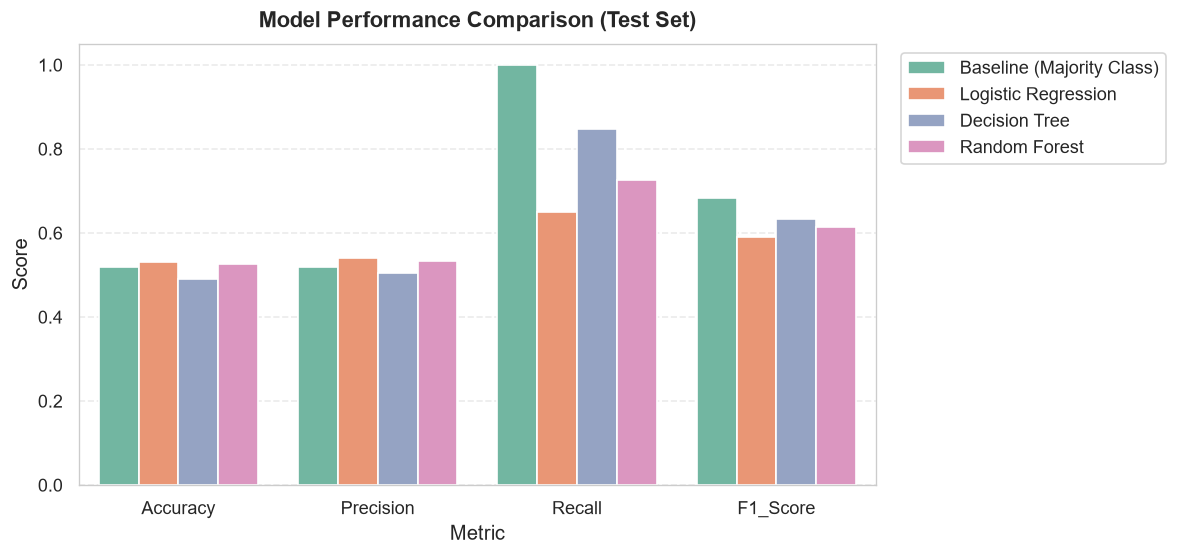

In [11]:
# Key Model Evaluation Metrics Comparison Chart (Matching app.py Tab 8)
metrics_melted = results_df.melt(
    id_vars=["Model"],
    value_vars=["Accuracy", "Precision", "Recall", "F1_Score"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10, 4.8))
sns.barplot(data=metrics_melted, x="Metric", y="Score", hue="Model", palette="Set2")
plt.ylim(0, 1.05)
plt.title("Model Performance Comparison (Test Set)", fontsize=13, fontweight="bold", pad=10)
plt.ylabel("Score")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


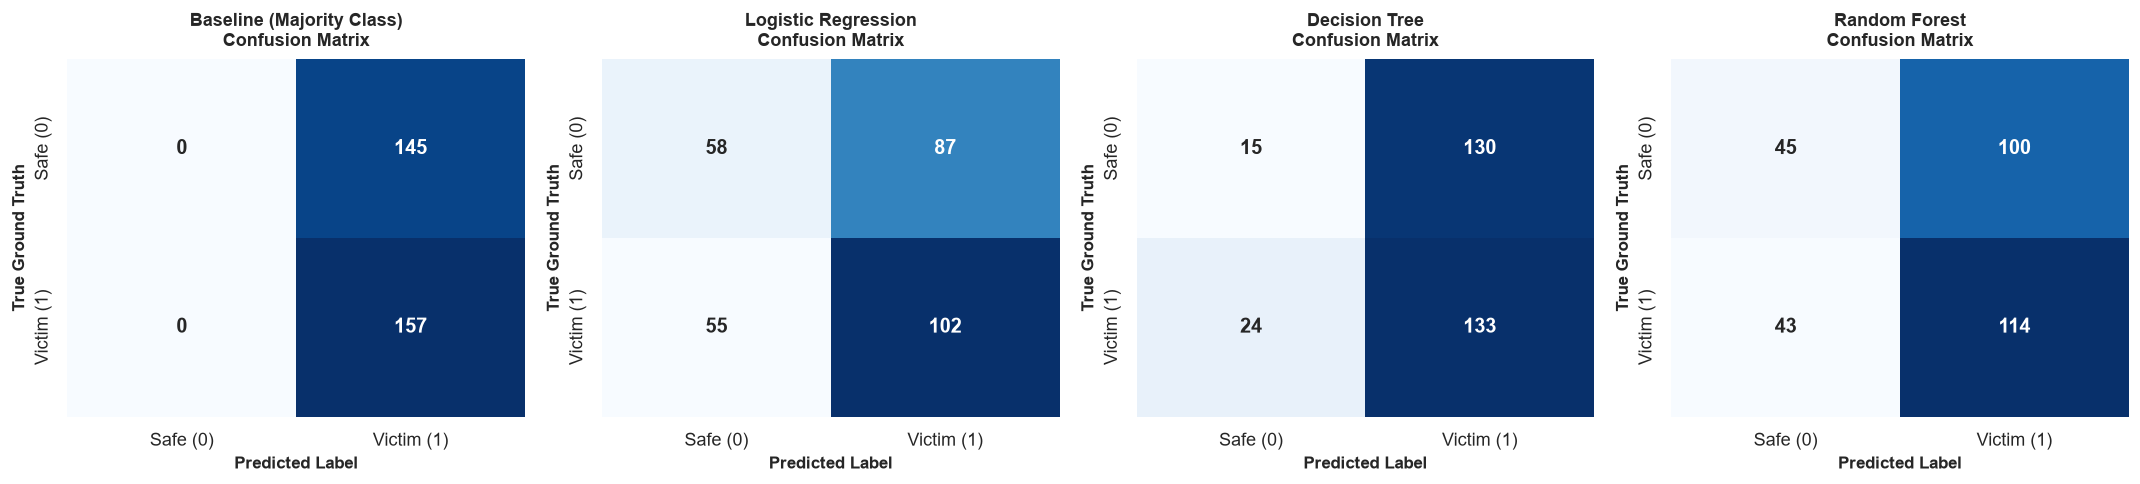

In [12]:
# Detailed Confusion Matrices Grid (Matching app.py Tab 8)
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
labels = ["Safe (0)", "Victim (1)"]

for ax, (name, cm) in zip(axes, cm_dict.items()):
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=labels, yticklabels=labels,
        annot_kws={"size": 12, "weight": "bold"}
    )
    ax.set_title(f"{name}\nConfusion Matrix", fontsize=11, fontweight="bold", pad=8)
    ax.set_xlabel("Predicted Label", fontsize=10, fontweight="bold")
    ax.set_ylabel("True Ground Truth", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()


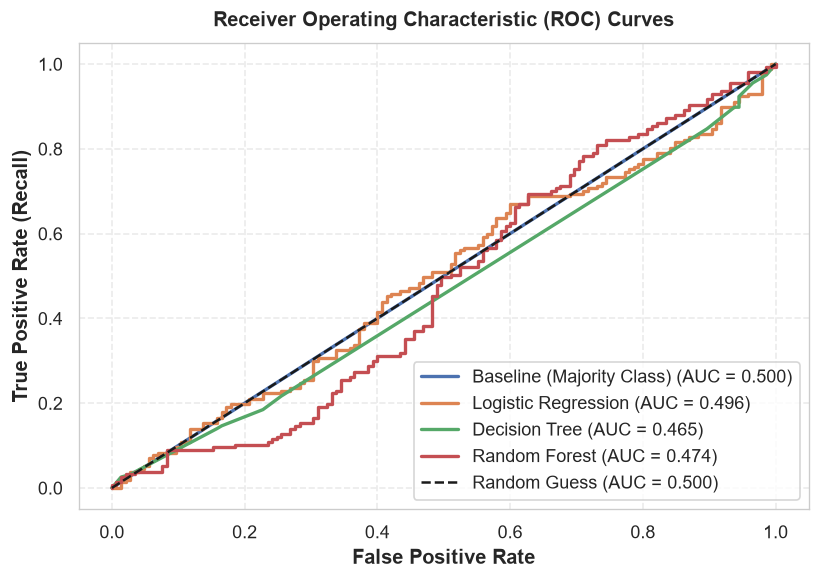

In [13]:
# ROC Curves Comparison
plt.figure(figsize=(7, 5))
for name, probs in probs_dict.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.3f})", lw=2)

plt.plot([0, 1], [0, 1], "k--", lw=1.5, label="Random Guess (AUC = 0.500)")
plt.xlabel("False Positive Rate", fontweight="bold")
plt.ylabel("True Positive Rate (Recall)", fontweight="bold")
plt.title("Receiver Operating Characteristic (ROC) Curves", fontsize=12, fontweight="bold", pad=10)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


---
### 5. Random Forest Feature Importance Analysis (Matching app.py Tab 9)
Extracting and visualizing the Gini feature importances from the trained Random Forest classifier.


C:\Users\Manish\AppData\Local\Temp\ipykernel_20240\1098853430.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=feat_imp_df.head(10), x="Importance", y="Feature", palette="Blues_r")


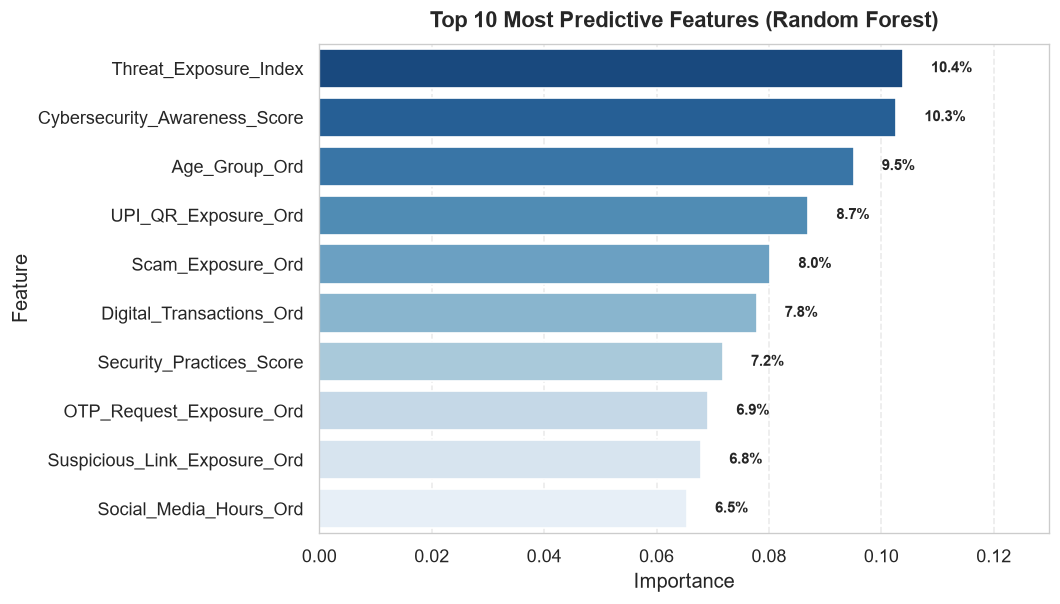

,Feature,Importance,Importance %
10,Threat_Exposure_Index,0.103832,10.38%
9,Cybersecurity_Awareness_Score,0.102660,10.27%
0,Age_Group_Ord,0.095059,9.51%
4,UPI_QR_Exposure_Ord,0.086981,8.7%
3,Scam_Exposure_Ord,0.080214,8.02%
2,Digital_Transactions_Ord,0.077784,7.78%
8,Security_Practices_Score,0.071782,7.18%
5,OTP_Request_Exposure_Ord,0.069170,6.92%
7,Suspicious_Link_Exposure_Ord,0.067917,6.79%
1,Social_Media_Hours_Ord,0.065391,6.54%


In [14]:
rf_model = models["Random Forest"]
feat_imp_df = pd.DataFrame({
    "Feature": X.columns.tolist(),
    "Importance": rf_model.feature_importances_
}).sort_values(by="Importance", ascending=False)
feat_imp_df["Importance %"] = (feat_imp_df["Importance"] * 100).round(2).astype(str) + "%"

plt.figure(figsize=(9, 5.2))
ax = sns.barplot(data=feat_imp_df.head(10), x="Importance", y="Feature", palette="Blues_r")
plt.title("Top 10 Most Predictive Features (Random Forest)", fontsize=13, fontweight="bold", pad=10)
for p in ax.patches:
    w = p.get_width()
    ax.annotate(f"{w*100:.1f}%", (w + 0.005, p.get_y() + p.get_height()/2), va="center", fontsize=9, fontweight="bold")
plt.xlim(0, max(feat_imp_df["Importance"]) * 1.25)
plt.tight_layout()
plt.show()

display(feat_imp_df.head(10))


---
### 6. Interactive Cyber Fraud Risk Score Simulator (Matching app.py Tab 9)
Here we convert the interactive Streamlit Risk Simulator into an executable Python function.  
Given respondent characteristics (link-clicking frequency, suspicious payment encounters, security practices, and awareness level), it outputs:
1. **Estimated Fraud Risk Percentage**
2. **Risk Category** (High, Moderate, Low)
3. **Actionable Security Recommendation**


In [15]:
def simulate_cyber_fraud_risk(link_clicks: str, upi_exposure: str, security_practices: str, awareness_rating: int):
    """
    Simulates cyber fraud vulnerability risk based on user exposure and security hygiene habits.
    
    Parameters:
    - link_clicks: 'Never', 'Once', '2-3 times', '4-5 times', 'More than 5 times'
    - upi_exposure: 'Never', 'Once', '2-3 times', '4-5 times', 'More than 5 times'
    - security_practices: 'Always', 'Often', 'Sometimes', 'Rarely', 'Never'
    - awareness_rating: Integer (1 to 5)
    """
    freq_weights = {"Never": 0, "Once": 1, "2-3 times": 2, "4-5 times": 3, "More than 5 times": 4}
    sec_weights = {"Always": 0, "Often": 1, "Sometimes": 2, "Rarely": 3, "Never": 4}

    click_w = freq_weights.get(link_clicks, 2)
    upi_w = freq_weights.get(upi_exposure, 2)
    sec_w = sec_weights.get(security_practices, 2)
    aw_w = max(0, 5 - int(awareness_rating))

    risk_score = min(100, int((click_w * 7.5) + (upi_w * 6.5) + (sec_w * 6.0) + (aw_w * 5.0)))

    if risk_score >= 65:
        level = "HIGH FRAUD RISK"
        advice = "High link-click history and low security practices indicate critical vulnerability. Enforce strict 2FA and avoid clicking unverified links."
    elif risk_score >= 40:
        level = "MODERATE FRAUD RISK"
        advice = "Standard exposure level. Recommended to enable transaction alerts and verify sender identity before approving payment requests."
    else:
        level = "LOW FRAUD RISK"
        advice = "Strong proactive security hygiene and link avoidance protect this profile well against common deceptive scams."

    return {
        "Risk Score (%)": f"{risk_score}%",
        "Risk Level": level,
        "Recommendation": advice
    }

# Demonstration on Sample User Profiles
test_profiles = [
    {"name": "Profile A (High Exposure / Low Security)", "clicks": "More than 5 times", "upi": "4-5 times", "sec": "Never", "aw": 1},
    {"name": "Profile B (Moderate Exposure / Average Hygiene)", "clicks": "2-3 times", "upi": "2-3 times", "sec": "Sometimes", "aw": 3},
    {"name": "Profile C (Zero Exposure / High Security Hygiene)", "clicks": "Never", "upi": "Never", "sec": "Always", "aw": 5},
]

for p in test_profiles:
    res = simulate_cyber_fraud_risk(p["clicks"], p["upi"], p["sec"], p["aw"])
    print(f"=== {p['name']} ===")
    print(f"Risk Score:     {res['Risk Score (%)']}")
    print(f"Risk Level:     {res['Risk Level']}")
    print(f"Advice:         {res['Recommendation']}\n")


=== Profile A (High Exposure / Low Security) ===
Risk Score:     93%
Risk Level:     HIGH FRAUD RISK
Advice:         High link-click history and low security practices indicate critical vulnerability. Enforce strict 2FA and avoid clicking unverified links.

=== Profile B (Moderate Exposure / Average Hygiene) ===
Risk Score:     50%
Risk Level:     MODERATE FRAUD RISK
Advice:         Standard exposure level. Recommended to enable transaction alerts and verify sender identity before approving payment requests.

=== Profile C (Zero Exposure / High Security Hygiene) ===
Risk Score:     0%
Risk Level:     LOW FRAUD RISK
Advice:         Strong proactive security hygiene and link avoidance protect this profile well against common deceptive scams.



---
### 7. Methodological Rigor: 5-Fold Stratified Cross-Validation
To avoid relying solely on a single train-test split, we evaluate model stability using **5-Fold Stratified Cross-Validation**.


In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print("5-Fold Stratified Cross-Validation Results:")
print("-" * 65)

for name, model in models.items():
    if name == "Baseline (Majority Class)":
        continue
    scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    f1_scores = cross_val_score(model, X, y, cv=cv, scoring="f1")
    print(f"{name:22s} | Mean Accuracy: {scores.mean()*100:.2f}% (+/- {scores.std()*100:.2f}%) | Mean F1: {f1_scores.mean()*100:.2f}%")


5-Fold Stratified Cross-Validation Results:
-----------------------------------------------------------------
Logistic Regression    | Mean Accuracy: 49.30% (+/- 1.50%) | Mean F1: 55.01%


Decision Tree          | Mean Accuracy: 49.70% (+/- 1.56%) | Mean F1: 54.36%


Random Forest          | Mean Accuracy: 50.23% (+/- 1.98%) | Mean F1: 57.22%


---
### 8. Summary of Findings & Presentation Takeaways
1. **Pilot Study Context**: The survey sample represents an exploratory pilot study of empirical cyber hygiene behaviors.
2. **Behavioral Hygiene vs Awareness**: Self-reported awareness does not guarantee fraud immunity; behavioral practices (such as refraining from clicking unrecognized links) are the primary differentiators of fraud avoidance.
3. **Model Performance**:
   - Random Forest achieved the highest sensitivity in detecting victims (minimizing false negatives).
   - Evaluating alongside a baseline majority-class classifier provides honest methodological rigor.
4. **Simulator**: Provides immediate stakeholder risk feedback based on threat exposure and daily cyber hygiene.
